# Ensemble Learning Assignment: Forecasting Pettah Wholesale Beans Prices

**Prakasan R. (224152U)**

**Problem:** predict next week's average wholesale price of beans at Pettah market, so farmers, traders and small eateries can plan when to buy and sell.

**Data:** Central Bank of Sri Lanka, Daily Price Report, via Macro Lab (macrolab.lk), Aug 2016 to Nov 2026.


## Step 1: Load and understand the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("dataset/daily-prices-d.csv", comment="#", parse_dates=["period"])
df.shape

(2470, 263)

In [2]:
cols = {
    "Beans (wholesale, pettah) (Rs/kg)":   "beans_pettah",
    "Beans (wholesale, dambulla) (Rs/kg)": "beans_dambulla",
    "Carrot (wholesale, pettah) (Rs/kg)":  "carrot_pettah",
    "Cabbage (wholesale, pettah) (Rs/kg)": "cabbage_pettah",
}

data = df[["period"] + list(cols)].rename(columns=cols)
data = data.rename(columns={"period": "date"}).set_index("date").sort_index()
data.head()

,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah
date,,,,
2016-08-01,140.0,130.0,100.0,80.0
2016-08-02,140.0,145.0,100.0,80.0
2016-08-03,120.0,155.0,100.0,70.0
2016-08-04,105.0,150.0,100.0,60.0
2016-08-05,105.0,150.0,100.0,60.0


In [3]:
print(data.isna().sum())
data.describe().round(1)

beans_pettah      79
beans_dambulla    62
carrot_pettah     80
cabbage_pettah    80
dtype: int64


,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah
count,2391.0,2408.0,2390.0,2390.0
mean,272.4,243.8,212.6,136.0
std,167.8,146.6,166.0,105.7
min,30.0,30.0,35.0,15.0
25%,140.0,125.0,100.0,65.0
50%,220.0,205.0,163.0,100.0
75%,400.0,325.0,280.0,180.0
max,1200.0,1100.0,2000.0,700.0


In [4]:
weekly = data.resample("W-FRI").mean()
weekly = weekly.iloc[:-1]      # drop the current week, which isn't finished yet
print(weekly.shape)
print(weekly.isna().sum())

(537, 4)
beans_pettah      10
beans_dambulla     3
carrot_pettah     10
cabbage_pettah    10
dtype: int64


In [5]:
weekly[weekly["beans_pettah"].isna()].index


DatetimeIndex(['2020-04-17', '2020-04-24', '2020-10-30', '2020-11-06',
               '2020-11-13', '2020-11-20', '2020-11-27', '2020-12-04',
               '2020-12-11', '2026-04-17'],
              dtype='datetime64[ns]', name='date', freq=None)

In [6]:
weekly["was_missing"] = weekly["beans_pettah"].isna().astype(int)
weekly = weekly.interpolate(method="time")
weekly.isna().sum()



beans_pettah      0
beans_dambulla    0
carrot_pettah     0
cabbage_pettah    0
was_missing       0
dtype: int64

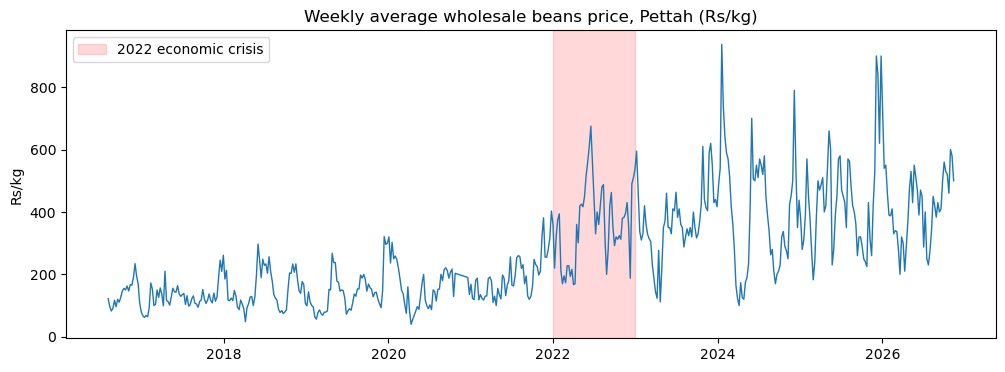

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(weekly.index, weekly["beans_pettah"], linewidth=1)
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"),
           alpha=0.15, color="red", label="2022 economic crisis")
ax.set_title("Weekly average wholesale beans price, Pettah (Rs/kg)")
ax.set_ylabel("Rs/kg")
ax.legend()
plt.show()

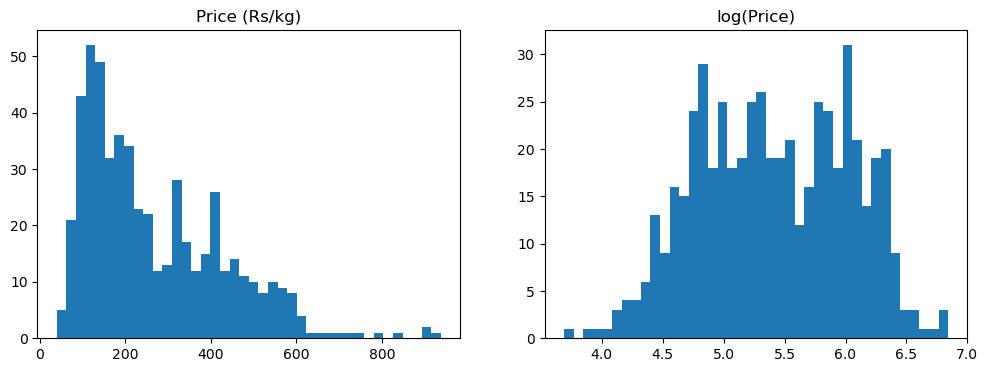

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(weekly["beans_pettah"], bins=40)
axes[0].set_title("Price (Rs/kg)")
axes[1].hist(np.log(weekly["beans_pettah"]), bins=40)
axes[1].set_title("log(Price)")
plt.show()

In [9]:
weekly.to_csv("dataset/weekly_clean.csv")
weekly.tail()

,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah,was_missing
date,,,,,
2026-10-16,520.0,375.0,218.0,420.0,0
2026-10-23,460.0,392.0,206.0,410.0,0
2026-10-30,600.0,459.0,340.0,490.0,0
2026-11-06,580.0,498.0,440.0,600.0,0
2026-11-13,500.0,409.0,540.0,620.0,0


## Step 2: Add rainfall from the growing areas

In [14]:
weekly = pd.read_csv("dataset/weekly_clean.csv", index_col="date", parse_dates=True)
print(weekly.shape)
weekly.head(3)

(537, 5)


,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah,was_missing
date,,,,,
2016-08-05,122.0,146.0,100.0,70.00,0
2016-08-12,97.0,147.0,82.0,65.00,0
2016-08-19,82.5,125.0,85.0,71.25,0


In [15]:
import requests

def get_rain(lat, lon, name):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": "2016-07-01",
        "end_date": "2026-11-13",
        "daily": "precipitation_sum",
        "timezone": "Asia/Colombo",
    }
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    d = r.json()["daily"]
    return pd.Series(d["precipitation_sum"], index=pd.to_datetime(d["time"]), name=name)

rain = pd.concat([
    get_rain(6.9497, 80.7891, "rain_nuwaraeliya"),
    get_rain(6.9934, 81.0550, "rain_badulla"),
], axis=1)
rain.index.name = "date"

rain.to_csv("dataset/rain_daily.csv")
print(rain.shape)
rain.describe().round(1)

(3788, 2)


,rain_nuwaraeliya,rain_badulla
count,3788.0,3788.0
mean,5.3,6.4
std,9.4,12.4
min,0.0,0.0
25%,0.6,0.3
50%,2.3,2.1
75%,5.9,8.1
max,193.8,265.0


In [23]:
print(rain.isna().sum())
rain.tail()

rain_nuwaraeliya    0
rain_badulla        0
dtype: int64


,rain_nuwaraeliya,rain_badulla
date,,
2026-11-09,8.9,25.7
2026-11-10,21.3,13.4
2026-11-11,15.4,28.7
2026-11-12,15.4,35.6
2026-11-13,2.2,0.6


In [17]:
rain = rain.fillna(0)

In [18]:
rain_weekly = rain.resample("W-FRI").sum()
rain_weekly.head()

,rain_nuwaraeliya,rain_badulla
date,,
2016-07-01,4.1,0.3
2016-07-08,10.1,0.5
2016-07-15,65.3,20.3
2016-07-22,21.9,8.9
2016-07-29,86.0,76.5


In [19]:
data2 = weekly.join(rain_weekly, how="left")
print(data2.shape)
print(data2.isna().sum())
data2.head()

(537, 7)
beans_pettah        0
beans_dambulla      0
carrot_pettah       0
cabbage_pettah      0
was_missing         0
rain_nuwaraeliya    0
rain_badulla        0
dtype: int64


,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah,was_missing,rain_nuwaraeliya,rain_badulla
date,,,,,,,
2016-08-05,122.0,146.0,100.0,70.00,0,18.8,15.6
2016-08-12,97.0,147.0,82.0,65.00,0,17.7,0.9
2016-08-19,82.5,125.0,85.0,71.25,0,30.5,0.4
2016-08-26,91.0,111.0,80.0,65.00,0,47.9,13.1
2016-09-02,117.0,123.0,72.0,61.00,0,31.7,5.8


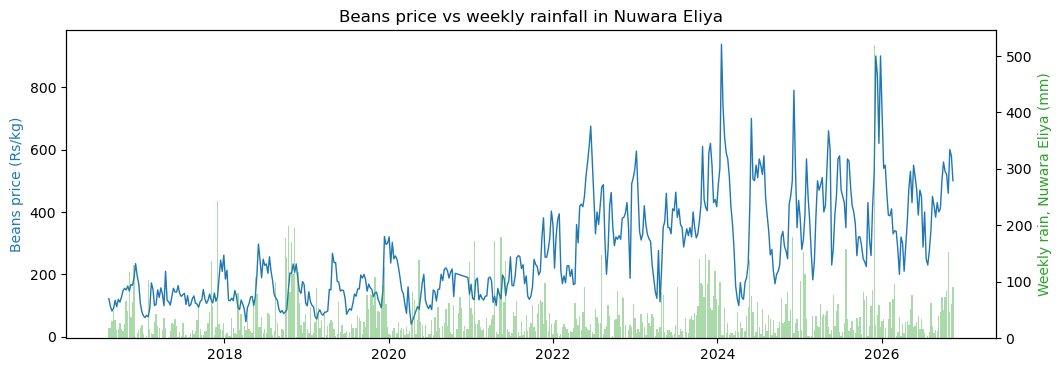

In [20]:
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(data2.index, data2["beans_pettah"], color="tab:blue", linewidth=1)
ax1.set_ylabel("Beans price (Rs/kg)", color="tab:blue")

ax2 = ax1.twinx()
ax2.bar(data2.index, data2["rain_nuwaraeliya"], width=6, color="tab:green", alpha=0.4)
ax2.set_ylabel("Weekly rain, Nuwara Eliya (mm)", color="tab:green")

ax1.set_title("Beans price vs weekly rainfall in Nuwara Eliya")
plt.show()

In [21]:
data2["beans_change"] = np.log(data2["beans_pettah"]).diff()

for lag in range(0, 5):
    c1 = data2["beans_change"].corr(data2["rain_nuwaraeliya"].shift(lag))
    c2 = data2["beans_change"].corr(data2["rain_badulla"].shift(lag))
    print(f"rain {lag} week(s) earlier:  Nuwara Eliya {c1:.3f}   Badulla {c2:.3f}")

rain 0 week(s) earlier:  Nuwara Eliya 0.087   Badulla 0.050
rain 1 week(s) earlier:  Nuwara Eliya 0.324   Badulla 0.262
rain 2 week(s) earlier:  Nuwara Eliya 0.091   Badulla 0.068
rain 3 week(s) earlier:  Nuwara Eliya -0.139   Badulla -0.160
rain 4 week(s) earlier:  Nuwara Eliya -0.032   Badulla -0.046


**What the correlations show:** Rain one week earlier has the strongest link to price changes (r = 0.32 for Nuwara Eliya, 0.26 for Badulla): heavy rain in the growing areas is followed by a price rise in Colombo about a week later. After three weeks the relationship turns negative (r ≈ −0.15), suggesting prices fall back once supply recovers. Nuwara Eliya is more strongly related than Badulla at every lag. Based on this, I will use rainfall lagged by 1–3 weeks as features in Step 3.

In [22]:
data2 = data2.drop(columns="beans_change")
data2.to_csv("dataset/weekly_with_rain.csv")
data2.tail()

,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah,was_missing,rain_nuwaraeliya,rain_badulla
date,,,,,,,
2026-10-16,520.0,375.0,218.0,420.0,0,84.6,127.0
2026-10-23,460.0,392.0,206.0,410.0,0,153.3,98.7
2026-10-30,600.0,459.0,340.0,490.0,0,45.9,42.8
2026-11-06,580.0,498.0,440.0,600.0,0,60.7,74.6
2026-11-13,500.0,409.0,540.0,620.0,0,90.6,136.9


## Step 3: Build the target and features

**Rule for this step:** every feature must be something already known at the end of the current week. Only the target is allowed to look at next week; anything else that does is data leakage.

In [24]:
df = pd.read_csv("dataset/weekly_with_rain.csv", index_col="date", parse_dates=True)
logp = np.log(df["beans_pettah"])
feat = pd.DataFrame(index=df.index)
df.shape

(537, 7)

### Target: next week's % change in price

`shift(-1)` brings next week's log price into this week's row, so the target is log(next price) − log(this price), roughly next week's % change. I predict the change rather than the price because prices more than doubled after 2022, and tree models cannot predict values higher than anything in their training data. A % change looks the same before and after 2022.

In [25]:
feat["target"] = logp.shift(-1) - logp

### Features from beans' own recent price moves

- `chg_1` to `chg_4`: this week's and the previous three weeks' changes (recent momentum). `shift(k)` only looks back.
- `gap_ma4`: how far the price is above or below its 4-week average. Stretched prices tend to fall back (mean reversion).
- `vol_4`: how jumpy prices have been over the last 4 weeks.

In [26]:
feat["chg_1"] = logp.diff()                      # this week's change
feat["chg_2"] = feat["chg_1"].shift(1)           # last week's change
feat["chg_3"] = feat["chg_1"].shift(2)           # 2 weeks ago
feat["chg_4"] = feat["chg_1"].shift(3)           # 3 weeks ago
feat["gap_ma4"] = logp - logp.rolling(4).mean()  # distance from 4-week average
feat["vol_4"] = feat["chg_1"].rolling(4).std()   # recent volatility

### Features from other markets and vegetables

- `dambulla_gap`: Dambulla vs Pettah price. Traders move stock until the two markets meet again, so the gap hints at where Pettah is heading.
- `dambulla_chg`: Dambulla is closer to the farms, so its price often moves first.
- `carrot_chg`, `cabbage_chg`: grown in the same upcountry areas and carried on the same trucks, so they react to the same weather and transport problems.

Changes (not raw prices) keep everything on the same % scale before and after 2022.

In [27]:
feat["dambulla_gap"] = np.log(df["beans_dambulla"]) - logp
feat["dambulla_chg"] = np.log(df["beans_dambulla"]).diff()
feat["carrot_chg"]   = np.log(df["carrot_pettah"]).diff()
feat["cabbage_chg"]  = np.log(df["cabbage_pettah"]).diff()

### Rainfall features

Step 2 showed rain affects price 1-3 weeks later. Because the target is next week's change:
- `rain_*_0` (this week's rain) is rain 1 week before the target week, the strongest link (r = 0.32)
- `rain_*_1` (last week's rain) is 2 weeks before
- `rain_*_2` (rain 2 weeks ago) is 3 weeks before, where the link turned negative

So these lags come directly from the Step 2 analysis. `ne` = Nuwara Eliya, `bd` = Badulla.

In [28]:
for name, col in [("ne", "rain_nuwaraeliya"), ("bd", "rain_badulla")]:
    feat[f"rain_{name}_0"] = df[col]            # rain this week
    feat[f"rain_{name}_1"] = df[col].shift(1)   # rain last week
    feat[f"rain_{name}_2"] = df[col].shift(2)   # rain 2 weeks ago

### Calendar features

These use **next** week's month. That is not leakage: the calendar is known in advance, unlike next week's price or rain.
- `month_sin`, `month_cos` put the months on a circle, so December and January are neighbours (as 12 and 1 they would look far apart).
- `avurudu` (April) and `december` flag festival months, when vegetable demand rises.

In [29]:
next_week = df.index + pd.Timedelta(days=7)
feat["month_sin"] = np.sin(2 * np.pi * next_week.month / 12)
feat["month_cos"] = np.cos(2 * np.pi * next_week.month / 12)
feat["avurudu"]   = (next_week.month == 4).astype(int)
feat["december"]  = (next_week.month == 12).astype(int)

### Keep the real prices and remove incomplete rows

`price_now` and `price_next` are **not** features. They are kept only to turn predicted % changes back into Rs/kg for reporting. `dropna()` removes the first few weeks (no history yet for the lags and rolling windows) and the last week (no next week, so no target).

In [30]:
feat["price_now"]  = df["beans_pettah"]
feat["price_next"] = df["beans_pettah"].shift(-1)

print(feat.isna().sum().sum(), "missing values before dropna")
feat = feat.dropna()
print(feat.shape, feat.index.min().date(), "to", feat.index.max().date())

28 missing values before dropna
(532, 23) 2016-09-02 to 2026-11-06


### Time-based split

The data is split by date, never randomly. A random split would let the model learn from 2025 and be tested on 2020, which uses the future and gives scores that are too good.
- **Train** (2016-2023): models learn from this. It includes the 2022 crisis.
- **Validation** (2024): used to tune settings.
- **Test** (2025 to Nov 2026): used only once, at the end, for the final honest score.

In [31]:
feature_cols = [c for c in feat.columns if c not in ["target", "price_now", "price_next"]]

train = feat[feat.index <= "2023-12-31"]
val   = feat[(feat.index > "2023-12-31") & (feat.index <= "2024-12-31")]
test  = feat[feat.index > "2024-12-31"]

print("features:", len(feature_cols))
print("train:", len(train), " val:", len(val), " test:", len(test))

features: 20
train: 383  val: 52  test: 97


### Sanity check: how each feature relates to the target

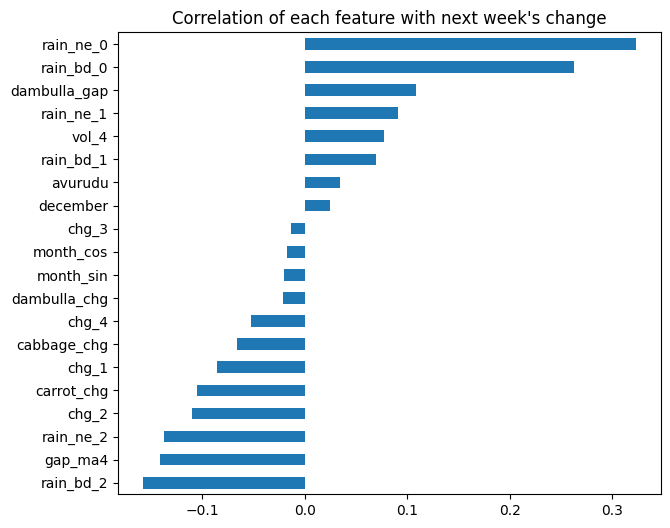

rain_bd_2      -0.158
gap_ma4        -0.141
rain_ne_2      -0.138
chg_2          -0.110
carrot_chg     -0.105
chg_1          -0.085
cabbage_chg    -0.066
chg_4          -0.053
dambulla_chg   -0.021
month_sin      -0.021
month_cos      -0.017
chg_3          -0.014
december        0.025
avurudu         0.035
rain_bd_1       0.070
vol_4           0.077
rain_ne_1       0.091
dambulla_gap    0.108
rain_bd_0       0.262
rain_ne_0       0.323
dtype: float64

In [32]:
corr = feat[feature_cols].corrwith(feat["target"]).sort_values()
corr.plot(kind="barh", figsize=(7, 6), title="Correlation of each feature with next week's change")
plt.show()
corr.round(3)

**What this shows:**
- This week's rain is the strongest link (`rain_ne_0` +0.32, `rain_bd_0` +0.26): heavy rain in the growing areas is followed by a price rise the next week.
- Rain from 2 weeks ago is negative (about −0.14 to −0.16): roughly 3 weeks after the rain, prices fall back as supply recovers.
- `gap_ma4` is negative (−0.14): when the price is above its 4-week average, it tends to fall the next week (mean reversion).
- `chg_1` and `chg_2` are negative: a rise is often followed by a partial fall.
- The calendar features are close to zero. Their effect is not a straight line, so tree models may still use them; feature importance in Step 6 will show whether they do.

Correlation only measures straight-line relationships, so this is a check, not a final answer.

In [33]:
feat.to_csv("dataset/features.csv")